   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
Inertia: [600.0, 223.73200573676345, 140.96581663074699, 114.61788585776678, 91.29544474066982, 81.75658187204955, 71.31982095188795, 62.65176715031906, 55.26184119603465, 50.62316902954044]


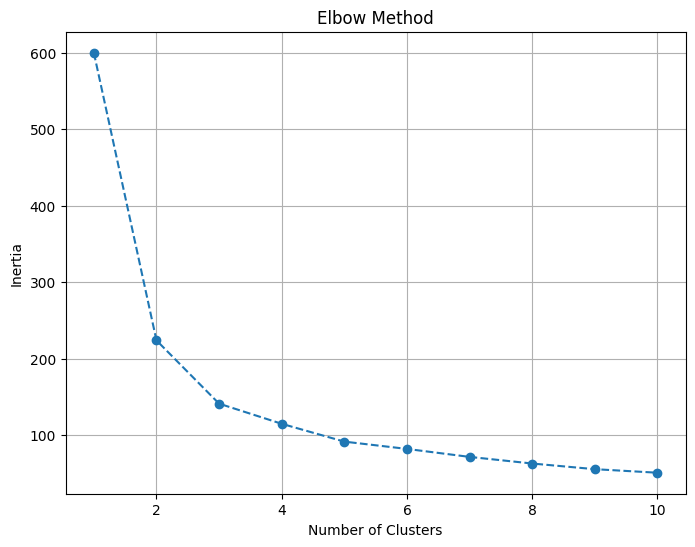


Cluster Assignments:
   Cluster
0        1
1        1
2        1
3        1
4        1
5        1
6        1
7        1
8        1
9        1

Cluster Centers:
[[-0.05021989 -0.88029181  0.34753171  0.28206327]
 [-1.01457897  0.84230679 -1.30487835 -1.25512862]
 [ 1.13597027  0.09659843  0.996271    1.01717187]]


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load the Iris dataset
df = pd.read_csv("iris.csv")

print(df.head())

# Select features (exclude Id and Species)
X = df.iloc[:, 1:-1]

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Determine optimal number of clusters using Elbow Method
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

print("Inertia:", inertia)

# Plot Elbow Curve
plt.figure(figsize=(8, 6))
plt.plot(range(1, 11), inertia, marker='o', linestyle='--')
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid()
plt.show()

# Apply K-Means with optimal K = 3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
y_pred = kmeans.fit_predict(X_scaled)

# Display cluster assignments
df['Cluster'] = y_pred

print("\nCluster Assignments:")
print(df[['Cluster']].head(10))

print("\nCluster Centers:")
print(kmeans.cluster_centers_)
